In [52]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()
# 오류 발생시
sklearn.set_config(display="text")

In [53]:
base_path = r"E:\kdt_0900_sal\ml\resource\dataset"

In [54]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

os.makedirs(base_path, exist_ok=True)
api.dataset_download_files(r"alxmamaev/flowers-recognition", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/alxmamaev/flowers-recognition
다운로드 완료


In [55]:
file_path = r"E:\kdt_0900_sal\ml\resource\dataset\flowers"
base_dataset = ImageFolder(root=file_path, transform=None)
print(len(base_dataset))

4317


In [56]:
total_size = len(base_dataset)
train_size = int(total_size * 0.8)
val_size = total_size - train_size

In [57]:
print(train_size, val_size)

3453 864


In [58]:
train_subset, val_subset = random_split(base_dataset, [train_size, val_size])

In [59]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [60]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [61]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
val_dataset = DatasetWrapper(val_subset, transform=val_transform)

In [62]:
print(len(train_dataset), len(val_dataset))

3453 864


In [63]:
class_dict = dict(enumerate(base_dataset.classes))
print(class_dict)

{0: 'daisy', 1: 'dandelion', 2: 'rose', 3: 'sunflower', 4: 'tulip'}


In [64]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [65]:
print(len(base_dataset)) # 전체 수
print(len(train_dataset), len(val_dataset)) # train, val 수
print(len(base_dataset.classes)) # 클래스 수
print(base_dataset.class_to_idx) # 라벨 매핑

4317
3453 864
5
{'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}


In [66]:
imgs, labels = next(iter(train_dataloader))

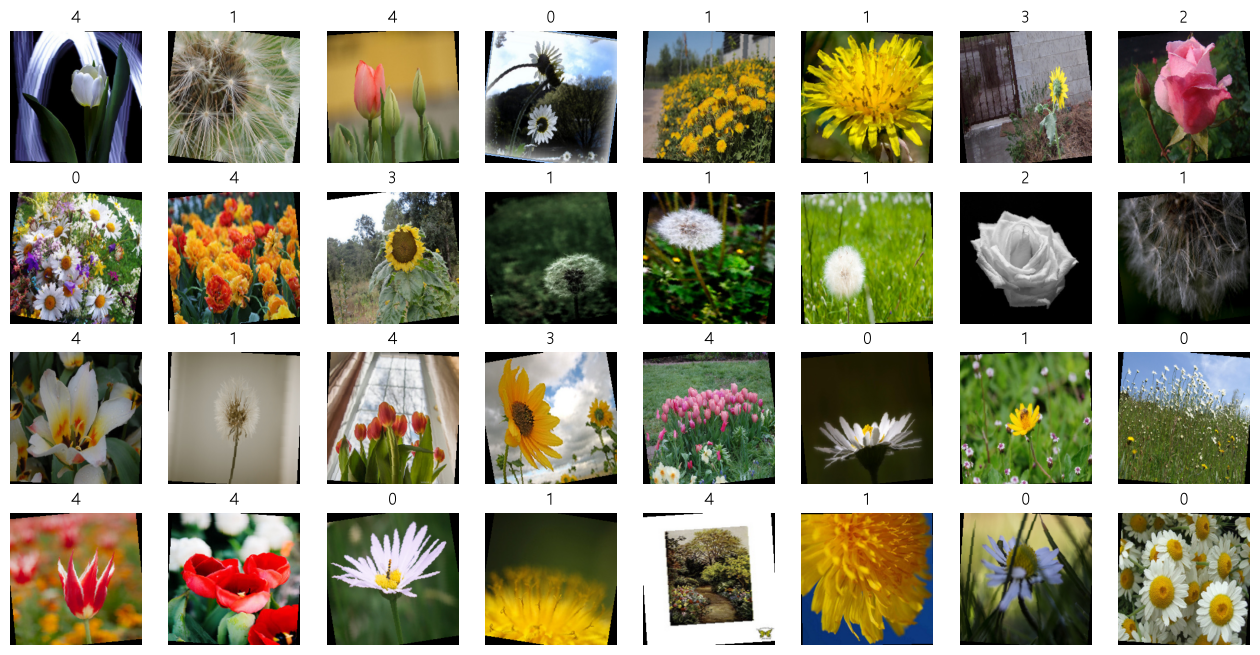

In [67]:
imgs, labels = next(iter(train_dataloader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(label.item())
    ax.axis("off")

plt.show()

In [68]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cpu


In [69]:
model = models.resnet18(weights="IMAGENET1K_V1").to(device)

In [70]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [71]:
for param in model.parameters():
    param.requires_grad = False

In [72]:
model.avgpool = nn.AdaptiveAvgPool2d((1, 1))
model.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 5)
).to(device)

In [73]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [74]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스의 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [75]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [76]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================={model_name} 학습 종료 ============================")
    return history

In [77]:
history1 = train_model_multiclass(
    model=model,
    model_name = "checkpoints",
    train_loader=train_dataloader,
    val_loader=val_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

=========================Resnet_multiclass 학습 시작 ============================
[Batch 20/108] Batch Loss: 1.2630, Batch Accuracy: 46.88%
[Batch 40/108] Batch Loss: 0.9688, Batch Accuracy: 56.25%
[Batch 60/108] Batch Loss: 0.8812, Batch Accuracy: 71.88%
[Batch 80/108] Batch Loss: 0.4310, Batch Accuracy: 87.50%
[Batch 100/108] Batch Loss: 0.6296, Batch Accuracy: 81.25%
[Epoch: 1] | Train Loss: 0.8112 | Train Accuracy: 70.34%
[Epoch: 1] | Validation Loss: 0.4327 | Validation Accuracy: 85.07%
[Batch 20/108] Batch Loss: 0.3644, Batch Accuracy: 87.50%
[Batch 40/108] Batch Loss: 0.5690, Batch Accuracy: 78.12%
[Batch 60/108] Batch Loss: 0.5350, Batch Accuracy: 81.25%
[Batch 80/108] Batch Loss: 0.7275, Batch Accuracy: 71.88%
[Batch 100/108] Batch Loss: 0.3896, Batch Accuracy: 84.38%
[Epoch: 2] | Train Loss: 0.5034 | Train Accuracy: 82.02%
[Epoch: 2] | Validation Loss: 0.3916 | Validation Accuracy: 86.11%
[Batch 20/108] Batch Loss: 0.8911, Batch Accuracy: 71.88%
[Batch 40/108] Batch Loss: 0.3243,

In [90]:
best_model_path = os.path.join(base_path, r"weights", r"checkpoints", r"best_model.pth")

In [91]:
model.load_state_dict(torch.load(best_model_path))
model = model.to(device)

In [92]:
model.eval()

val_loss, val_acc = evaluate_multiclass(
    model=model,
    dataloader=val_dataloader,
    criterion=criterion,
    device=device
)

print(f"최종 모델의 평가")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2f}%")

최종 모델의 평가
Validation Loss: 0.3317
Validation Accuracy: 89.70%


In [93]:
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for X_batch, y_batch in val_dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        outputs = model(X_batch)
        preds = outputs.argmax(dim=1)

        y_true.extend(y_batch.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

f1 = f1_score(y_true, y_pred, average="weighted")

print(f"F1-Score: {f1:.4f}")

F1-Score: 0.8968


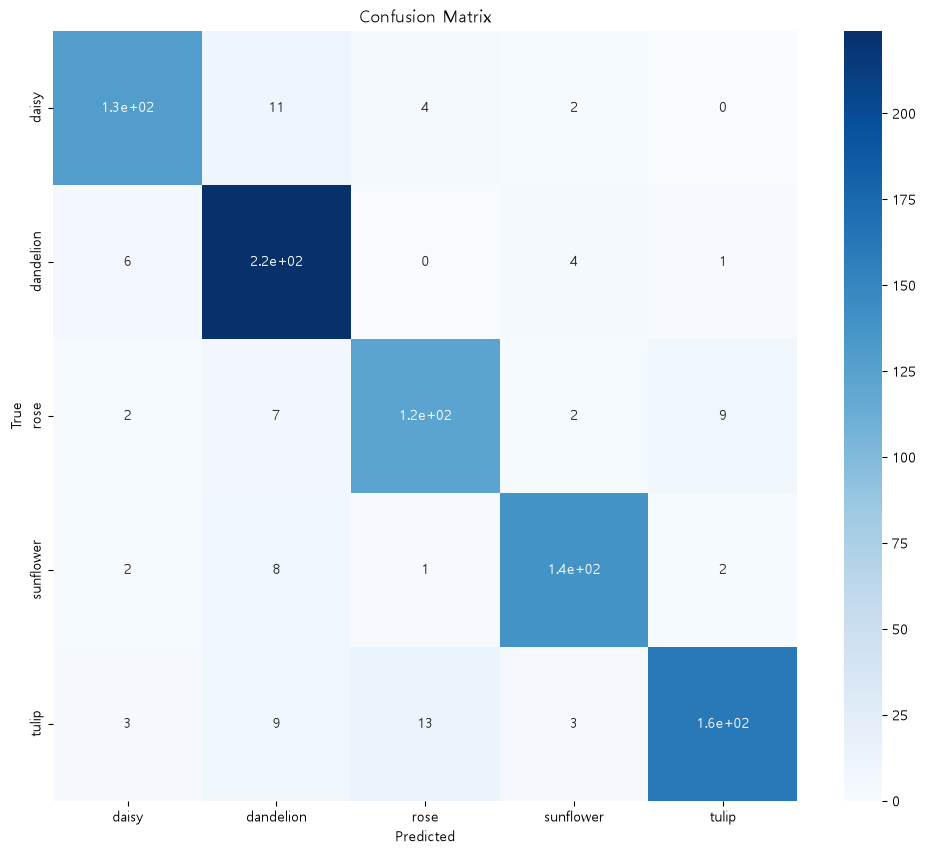

In [94]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    xticklabels=base_dataset.classes,
    yticklabels=base_dataset.classes
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [121]:
model.eval()

incorrect_samples = []

with torch.no_grad():
    for imgs, labels in val_dataloader:
        imgs = imgs.to(device)

        preds = model(imgs)
        probs = torch.softmax(preds, dim=1)
        pred_labels = preds.argmax(dim=1).cpu()

        incorrect_mask = (pred_labels != labels)

        if incorrect_mask.any():
            for img, label, pred, prob in zip(imgs[incorrect_mask], labels[incorrect_mask], pred_labels[incorrect_mask], probs.cpu()[incorrect_mask]):
                incorrect_samples.append({
                    "img": img,
                    "true_label": label.item(),
                    "pred_label": pred.item(),
                    "prob": prob[pred].item()
                })
        if len(incorrect_samples) >= 8:
            break

for sample in incorrect_samples[:5]:
    print(f"정답: {class_dict[sample["true_label"]]} | 예측: {class_dict[sample["pred_label"]]} | 확률: {sample["prob"] * 100:.2f}%")

정답: tulip | 예측: rose | 확률: 80.38%
정답: sunflower | 예측: dandelion | 확률: 92.77%
정답: rose | 예측: dandelion | 확률: 41.38%
정답: sunflower | 예측: dandelion | 확률: 57.25%
정답: daisy | 예측: dandelion | 확률: 46.56%


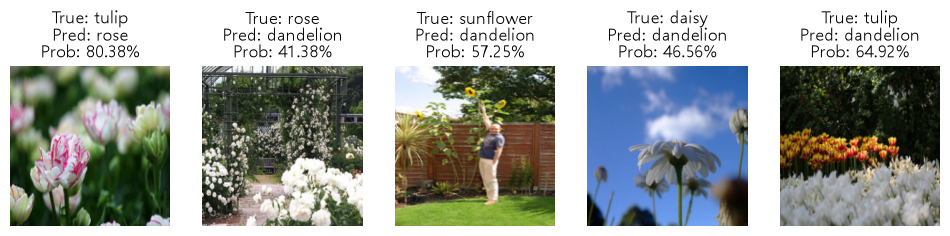

In [117]:
fig, axes = plt.subplots(1, 5, figsize=(12, 10))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

selected_samples = [incorrect_samples[0],incorrect_samples[2],incorrect_samples[3],incorrect_samples[4],incorrect_samples[6]]

for ax, sample in zip(axes, selected_samples):
    img = sample["img"].cpu()
    label = sample["true_label"]
    pred = sample["pred_label"]
    prob = sample["prob"] * 100

    img_np = img.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np * std + mean, 0, 1)

    ax.imshow(img_np)
    ax.set_title(f"True: {class_dict[label]}\nPred: {class_dict[pred]}\nProb: {prob:.2f}%")
    ax.axis("off")

plt.show()

In [118]:
img_path = r"E:\kdt_0900_sal\ml\resource\145862135_ab710de93c_n.jpg"

예측 결과: rose (확률: 98.5%, 클래스 번호: 2)


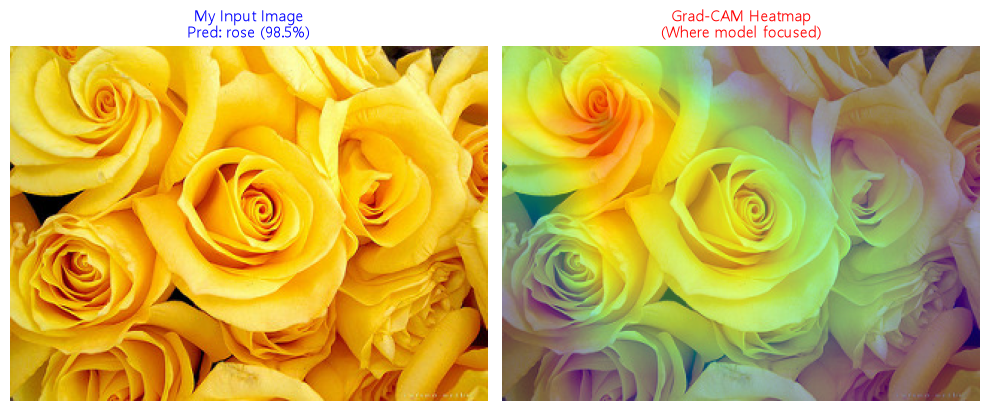

In [119]:
activations = None

def forward_hook(module, input, output):
    global activations
    output.requires_grad_(True)
    output.retain_grad()
    activations = output

target_layer = model.layer4[-1].conv2 
hook = target_layer.register_forward_hook(forward_hook)

original_image = Image.open(img_path).convert("RGB")
input_tensor = val_transform(original_image).unsqueeze(0).to(
    device
)  

model.eval()

output = model(input_tensor)
probs = F.softmax(output, dim=1)[0]
pred_idx = torch.argmax(probs).item()
pred_class = class_dict[pred_idx]
confidence = probs[pred_idx].item() * 100

print(f"예측 결과: {pred_class} (확률: {confidence:.1f}%, 클래스 번호: {pred_idx})")

model.zero_grad()

class_score = output[0, pred_idx]
class_score.backward()
gradients = activations.grad
pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])
weighted_activations = activations * pooled_gradients.view(1, -1, 1, 1)
heatmap = torch.mean(weighted_activations, dim=1).squeeze().cpu().detach().numpy()
heatmap = np.maximum(heatmap, 0)

if heatmap.max() != 0:
    heatmap /= heatmap.max() 

heatmap_uint8 = np.uint8(255 * heatmap)
heatmap_pil = Image.fromarray(heatmap_uint8).resize(
    original_image.size, Image.Resampling.BILINEAR
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title(f"My Input Image\nPred: {pred_class} ({confidence:.1f}%)", fontsize=11, color="blue",)
axes[0].axis("off")


axes[1].imshow(original_image)
axes[1].imshow(heatmap_pil, cmap="jet", alpha=0.4)
axes[1].set_title(f"Grad-CAM Heatmap\n(Where model focused)", fontsize=11, color="red")
axes[1].axis("off")

hook.remove()

plt.tight_layout()
plt.show()

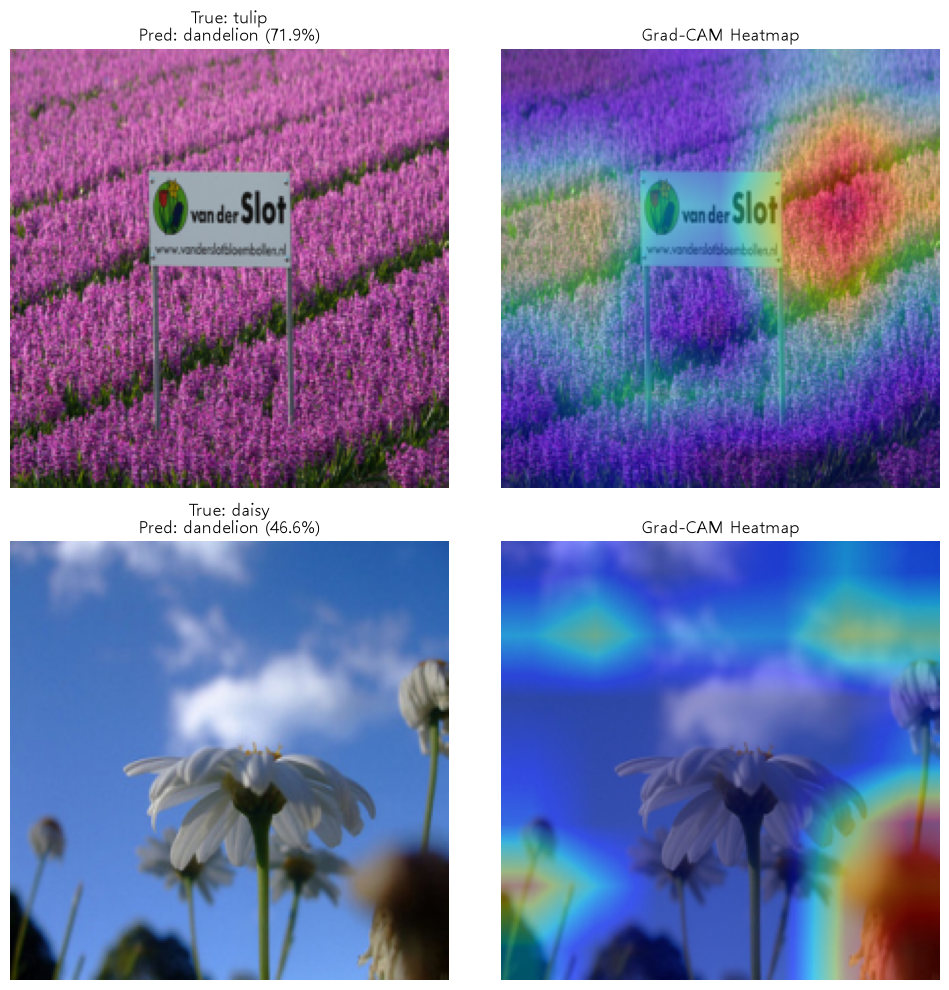

In [120]:
activations = None

def forward_hook(module, input, output):
    global activations
    output.requires_grad_(True)
    output.retain_grad()
    activations = output


target_layer = model.layer4[-1].conv2
hook = target_layer.register_forward_hook(forward_hook)

mean_t = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std_t = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

model.eval()

selected_samples = [incorrect_samples[7],incorrect_samples[4]]

for i, sample in enumerate(selected_samples):
    img = sample["img"]
    true_label = sample["true_label"]

    input_tensor = img.unsqueeze(0).to(device)

    output = model(input_tensor)

    probs = F.softmax(output, dim=1)[0]
    pred_idx = torch.argmax(probs).item()
    confidence = probs[pred_idx].item() * 100

    model.zero_grad()

    class_score = output[0, pred_idx]
    class_score.backward()

    gradients = activations.grad
    pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])

    weighted_activations = activations * pooled_gradients.view(1, -1, 1, 1)

    heatmap = torch.mean(weighted_activations, dim=1).squeeze()
    heatmap = torch.relu(heatmap).cpu().detach().numpy()

    if heatmap.max() != 0:
        heatmap /= heatmap.max()

    heatmap_uint8 = np.uint8(255 * heatmap)
    heatmap_pil = Image.fromarray(heatmap_uint8).resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    original_image = img * std_t + mean_t
    original_image = original_image.permute(1, 2, 0).numpy()
    original_image = np.clip(original_image, 0, 1)

    axes[i, 0].imshow(original_image)
    axes[i, 0].set_title(
        f"True: {class_dict[true_label]}\n"
        f"Pred: {class_dict[pred_idx]} ({confidence:.1f}%)"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(original_image)
    axes[i, 1].imshow(heatmap_pil, cmap="jet", alpha=0.4)
    axes[i, 1].set_title("Grad-CAM Heatmap")
    axes[i, 1].axis("off")

hook.remove()

plt.tight_layout()
plt.show()

In [116]:
history_df = pd.DataFrame({
    "Epoch": range(1, len(history1["train_loss"]) + 1),
    "Train Loss": history1["train_loss"],
    "Val Loss": history1["val_loss"],
    "Train Accuracy": history1["train_acc"],
    "Val Accuracy": history1["val_acc"]
})

display(history_df)

,Epoch,Train Loss,Val Loss,Train Accuracy,Val Accuracy
0,1,0.811169,0.432733,70.343431,85.069444
1,2,0.503434,0.391643,82.016284,86.111111
2,3,0.445323,0.339173,83.862149,88.194444
3,4,0.439438,0.403164,83.912037,85.879630
4,5,0.397732,0.331744,85.780851,89.699074
5,6,0.381374,0.328330,85.555356,89.004630
6,7,0.372203,0.339867,86.744692,88.425926
7,8,0.357651,0.389073,86.921296,85.416667
8,9,0.363046,0.363229,86.440374,86.921296
9,10,0.352079,0.325457,87.056992,89.351852
